In [1]:
import pandas as pd

In [2]:
data=pd.read_csv('/content/loan_data.csv')

In [3]:
# Check dataset dimensions
print("Dataset shape:", data.shape)

Dataset shape: (45000, 14)


In [4]:
# Display first 5 rows
display(data.head())

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [5]:
# Check data types and non-null values
print("\nDataset information:")
data.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_l

In [6]:
# Check missing values
print("\nMissing values per column:")
print(data.isnull().sum())


Missing values per column:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64


In [7]:
# Check duplicate rows
print("\nDuplicate rows:", data.duplicated().sum())


Duplicate rows: 0


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check attrition counts
print("Loan Staus Count:")
print(data["loan_status"].value_counts())

Loan Staus Count:
loan_status
0    35000
1    10000
Name: count, dtype: int64


In [9]:
# Calculate loan status percentages
status_counts = data["loan_status"].value_counts()
status_percentages = data["loan_status"].value_counts(normalize=True) * 100

print("Loan Status Counts:")
print(status_counts)

print("\nLoan Status Percentages:")
print(status_percentages.round(2))

Loan Status Counts:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Loan Status Percentages:
loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64


**Credit score vs loan status**

In [10]:
# Compare average credit score by loan status
credit_analysis = data.groupby("loan_status")["credit_score"].agg(
    ["mean", "median", "min", "max", "count"]
)

print("Credit Score Analysis by Loan Status:")
display(credit_analysis.round(2))

Credit Score Analysis by Loan Status:


,mean,median,min,max,count
loan_status,,,,,
0,632.81,640.0,390,850,35000
1,631.89,639.0,431,767,10000


**Visualization 📊**

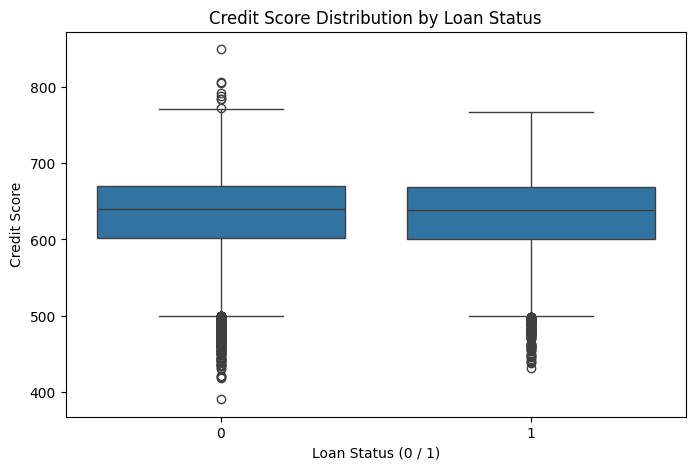

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="loan_status",
    y="credit_score"
)

plt.title("Credit Score Distribution by Loan Status")
plt.xlabel("Loan Status (0 / 1)")
plt.ylabel("Credit Score")

plt.show()

**Relationship Between Previous Loan Defaults and Loan Status**

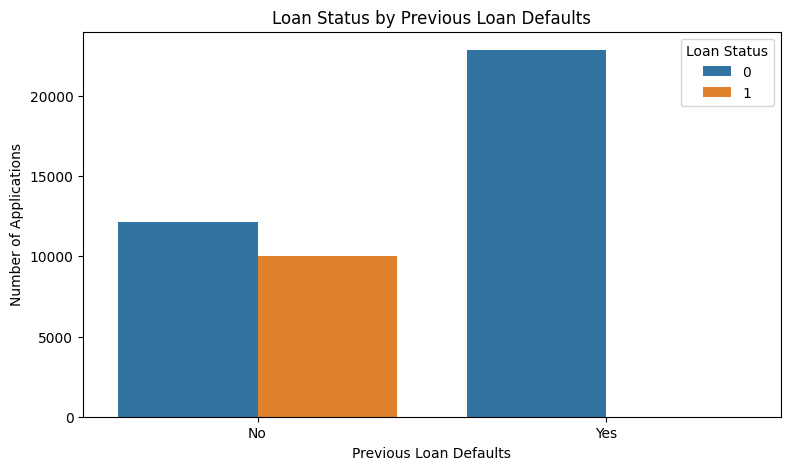

In [12]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=data,
    x="previous_loan_defaults_on_file",
    hue="loan_status"
)

plt.title("Loan Status by Previous Loan Defaults")
plt.xlabel("Previous Loan Defaults")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Status")

plt.show()

**Income Analysis by Loan Status**

In [13]:
#Summary statistics
# Analyze applicant income by loan status
income_analysis = data.groupby("loan_status")["person_income"].agg(
    ["mean", "median", "min", "max"]
)

print("Income Analysis by Loan Status:")
display(income_analysis.round(2))

Income Analysis by Loan Status:


,mean,median,min,max
loan_status,,,,
0,86157.04,72928.0,9595.0,7200766.0
1,59886.10,50629.0,8000.0,845636.0


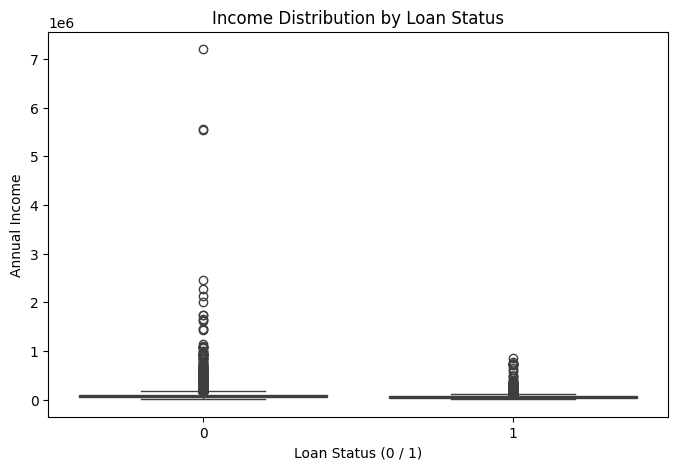

In [14]:
#Visualization
plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x="loan_status", y="person_income")

plt.title("Income Distribution by Loan Status")
plt.xlabel("Loan Status (0 / 1)")
plt.ylabel("Annual Income")

plt.show()

**Loan Amount Analysis by Loan Status**

In [15]:
# Analyze loan amount by loan status
loan_analysis = data.groupby("loan_status")["loan_amnt"].agg(
    ["mean", "median", "min", "max"]
)

print("Loan Amount Analysis by Loan Status:")
display(loan_analysis.round(2))

Loan Amount Analysis by Loan Status:


,mean,median,min,max
loan_status,,,,
0,9219.58,8000.0,500.0,35000.0
1,10855.69,9750.0,900.0,35000.0


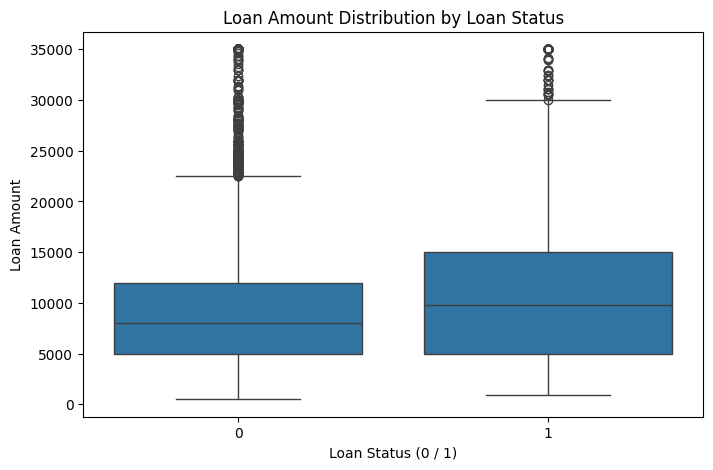

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x="loan_status", y="loan_amnt")

plt.title("Loan Amount Distribution by Loan Status")
plt.xlabel("Loan Status (0 / 1)")
plt.ylabel("Loan Amount")

plt.show()

##Key Findings

1. Loan Approval Status
- The dataset contains 45,000 loan applications.
- 10,000 applications (22.22%) were approved.
- 35,000 applications (77.78%) were rejected.

2. Credit Score Analysis
- The mean credit scores were similar for rejected applications (632.81) and approved applications (631.89).
- The median credit scores were also similar: 640 for rejected applications and 639 for approved applications.
- Further analysis may be needed to understand whether credit score patterns vary across different score ranges.

3. Income Analysis
- Rejected applications had a higher mean applicant income (86,157.04) than approved applications (59,886.10).
- The median income was also higher for rejected applications (72,928) than for approved applications (50,629).
- The maximum income in the rejected group was substantially higher than in the approved group, suggesting that the income distribution should be investigated further.

## Conclusion

The analysis shows differences in income between approved and rejected applications, while credit scores remain similar. Further analysis of other applicant characteristics may provide additional insights.